In [1]:
import importlib
import inspect
import os
from argparse import Namespace
import numpy as np

%load_ext autoreload
%autoreload 2



def get_all_dataset_names():
    return [
        dataset.split(".")[0]
        for dataset in os.listdir("dataset")
        if not dataset.find("__") > -1 and "py" in dataset
    ]


def get_all_datasets():
    datasets = {}
    for dataset in get_all_dataset_names():
        mod = importlib.import_module("dataset." + dataset)
        dataset_classes_name = [
            x
            for x in mod.__dir__()
            if "type" in str(type(getattr(mod, x)))
            and "DatasetBase" in str(inspect.getmro(getattr(mod, x))[1:])
        ]
        for d in dataset_classes_name:
            c = getattr(mod, d)
            datasets[c.NAME] = c
    return datasets


def get_dataset(dataset_name, accelerator, args: Namespace):
    """
    Returns the dataset object.
    """
    datasets_set = get_all_datasets()
    assert (
        dataset_name in datasets_set
    ), f"Dataset {dataset_name} not found. Available datasets: {datasets_set.keys()}"
    return datasets_set[dataset_name](accelerator, args)


In [2]:
from accelerate import Accelerator
accelerator = Accelerator()

# Configure args for Qwen2 model and dataset
args = Namespace()
args.model = "Qwen/Qwen2.5-0.5B"  # Using smaller Qwen2 model for testing
args.dataset = "MMLU-chem"  # Boolean Questions dataset (2-class classification)
args.add_space = False
args.max_seq_len = 300
args.batch_size = 16
args.is_s2s = False  # Qwen2 is decoder-only, not sequence-to-sequence
args.testing_set = "val"

print(f"Using model: {args.model}")
print(f"Using dataset: {args.dataset}")
# Create the dataset
try:
    dataset = get_all_datasets()['mcdataset'](accelerator, args)
    print(f"✅ Successfully created dataset with {dataset.num_labels} labels")
    
    # Get the dataloaders
    dataset.get_loaders()
    print(f"✅ Successfully created dataloaders")
    print(f"📊 Number of training samples: {dataset.num_samples}")
    print(f"🎯 Target token IDs: {dataset.target_ids}")
    
except Exception as e:
    print(f"❌ Error creating dataset: {e}")
    print("Available datasets:", list(get_all_datasets().keys()))

Using model: Qwen/Qwen2.5-0.5B
Using dataset: MMLU-chem
Loaded MMLU-chem dataset.
✅ Successfully created dataset with 4 labels
✅ Successfully created dataloaders
📊 Number of training samples: 96
🎯 Target token IDs: tensor([[32],
        [33],
        [34],
        [35]])


In [3]:
dataset.target_ids

tensor([[32],
        [33],
        [34],
        [35]])

In [105]:
# Explore the dataset structure
if 'dataset' in locals():
    print("=== Dataset Information ===")
    print(f"Dataset type: {type(dataset)}")
    print(f"Number of labels: {dataset.num_labels}")
    print(f"Tokenizer: {type(dataset.tokenizer)}")
    print(f"Tokenizer vocab size: {dataset.tokenizer.vocab_size}")
    
    # Check special tokens
    print("\n=== Special Tokens ===")
    print(f"BOS token: '{dataset.tokenizer.bos_token}' (ID: {dataset.tokenizer.bos_token_id})")
    print(f"EOS token: '{dataset.tokenizer.eos_token}' (ID: {dataset.tokenizer.eos_token_id})")
    print(f"PAD token: '{dataset.tokenizer.pad_token}' (ID: {dataset.tokenizer.pad_token_id})")
    print(f"UNK token: '{dataset.tokenizer.unk_token}' (ID: {dataset.tokenizer.unk_token_id})")
    
    # Target tokens for classification
    print(f"\n=== Target Tokens for Classification ===")
    print(f"Target IDs shape: {dataset.target_ids.shape}")
    print(f"Target token IDs: {dataset.target_ids.tolist()}")
    
    # Decode target tokens
    for i, target_id in enumerate(dataset.target_ids):
        decoded = dataset.tokenizer.decode(target_id, skip_special_tokens=True)
        print(f"Label {i}: token_id={target_id.item()} -> '{decoded}'")
    
    # Show a sample batch from train dataloader
    print("\n=== Sample Training Batch ===")
    try:
        sample_batch = next(iter(dataset.train_dataloader))
        print(f"Batch type: {type(sample_batch)}")
        print(f"Batch length: {len(sample_batch)}")
        
        # Handle BatchEncoding object
        batch_encoding = sample_batch[0]
        labels = sample_batch[1] if len(sample_batch) > 1 else None
        extra = sample_batch[2] if len(sample_batch) > 2 else None
        
        print(f"\nBatchEncoding keys: {list(batch_encoding.keys())}")
        
        # Get input_ids and attention_mask
        input_ids = batch_encoding['input_ids']
        attention_mask = batch_encoding.get('attention_mask', None)
        
        print(f"Input IDs shape: {input_ids.shape}")
        if attention_mask is not None:
            print(f"Attention mask shape: {attention_mask.shape}")
        if labels is not None:
            print(f"Labels shape: {labels.shape}")
            print(f"Sample labels: {labels[:5].tolist()}")
        if extra is not None:
            print(f"Extra tensor shape: {extra.shape}")
        
        # Show first sample
        print(f"\nFirst sample input IDs (first 20): {input_ids[0][:20].tolist()}")
        if attention_mask is not None:
            print(f"First sample attention mask (first 20): {attention_mask[0][:20].tolist()}")
        
        # Decode first sample
        decoded_text = dataset.tokenizer.decode(input_ids[0], skip_special_tokens=False)
        print(f"\nDecoded sample:\n{decoded_text}...")
        
        # Show the actual length vs padded length
        actual_length = attention_mask[0].sum().item() if attention_mask is not None else len(input_ids[0])
        print(f"\nSequence info:")
        print(f"Total length: {len(input_ids[0])}")
        print(f"Actual length (non-padded): {actual_length}")
        
    except Exception as e:
        print(f"Error exploring batch: {e}")
        import traceback
        traceback.print_exc()
else:
    print("❌ Dataset not created yet. Run the previous cell first.")

=== Dataset Information ===
Dataset type: <class 'dataset.S2SDataset_Classification.S2SDataset_Classification'>
Number of labels: 2
Tokenizer: <class 'transformers.models.qwen2.tokenization_qwen2_fast.Qwen2TokenizerFast'>
Tokenizer vocab size: 151643

=== Special Tokens ===
BOS token: 'None' (ID: None)
EOS token: '<|endoftext|>' (ID: 151643)
PAD token: '<|endoftext|>' (ID: 151643)
UNK token: 'None' (ID: None)

=== Target Tokens for Classification ===
Target IDs shape: torch.Size([2, 1])
Target token IDs: [[2514], [4049]]
Label 0: token_id=2514 -> 'True'
Label 1: token_id=4049 -> 'False'

=== Sample Training Batch ===
Batch type: <class 'tuple'>
Batch length: 3

BatchEncoding keys: ['input_ids', 'attention_mask']
Input IDs shape: torch.Size([4, 300])
Attention mask shape: torch.Size([4, 300])
Labels shape: torch.Size([4])
Sample labels: [1, 1, 1, 1]
Extra tensor shape: torch.Size([4])

First sample input IDs (first 20): [151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 15

In [4]:
sample_batch, label, target_id = next(iter(dataset.train_dataloader))
print(sample_batch['input_ids'].shape)
print(sample_batch['attention_mask'].shape)
print(label)
print(target_id)

torch.Size([16, 300])
torch.Size([16, 300])
tensor([3, 2, 3, 1, 1, 1, 0, 3, 2, 3, 3, 1, 0, 3, 3, 2])
tensor([35, 34, 35, 33, 33, 33, 32, 35, 34, 35, 35, 33, 32, 35, 35, 34])


### run with stored dataset

In [5]:
from src.qwen_jax import load_params_and_config, QwenForCausalLM
import jax
import jax.numpy as jnp
import numpy as np

%load_ext autoreload
%autoreload 2

params, config = load_params_and_config("datasets/model_exports/qwen2.5_0.5B_bfloat16")
jax_model = QwenForCausalLM(**config)
params

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


FrozenDict({
    params: {
        embed_tokens: {
            embedding: Array([[-0.0100708, 0.0419922, 0.0098877, ..., 0.00994873, 0.0151367,
                    -0.00704956],
                   [-0.0146484, 6.03199e-05, -0.0184326, ..., -0.00169373,
                    0.00311279, -0.00842285],
                   [-0.0366211, -0.00982666, 0.00698853, ..., -0.00775146,
                    -0.0170898, -0.000104904],
                   ...,
                   [0.0027771, -0.00939941, 0.00424194, ..., -0.00656128, -0.0106201,
                    0.0172119],
                   [0.0027771, -0.00939941, 0.00424194, ..., -0.00656128, -0.0106201,
                    0.0172119],
                   [0.0027771, -0.00939941, 0.00424194, ..., -0.00656128, -0.0106201,
                    0.0172119]], dtype=bfloat16),
        },
        layers_0: {
            input_layernorm: {
                weight: Array([-0.0461426, 0.0437012, -0.0244141, 0.0825195, -0.0410156,
                       0.0375977

In [6]:
with np.load("datasets/text_classification/boolq/train_data.npz") as data:
    input_ids = jnp.array(data['input_ids'])
    attention_mask = jnp.array(data['attention_mask'])
    labels = jnp.array(data['labels'])
    target_id = jnp.array(data['target_id'])
    all_target_ids = jnp.array(data['target_ids'])

input_ids.shape, attention_mask.shape, labels.shape, target_id.shape, all_target_ids.shape

((9424, 525), (9424, 525), (9424,), (9424,), (2, 1))

In [7]:
# Test forward pass with loaded Qwen model and dataset batch
# Assumes: jax_model, params, input_ids, attention_mask are already defined

# Forward pass (no gradient, inference mode)
outputs, inter = jax_model.apply(params, input_ids[:4], attention_mask[:4], train=False, mutable=['intermediates'])
print("Forward pass output shape:", outputs.shape)
print("Sample", outputs[0][-1])

Forward pass output shape: (4, 525, 151936)
Sample [4.21875 4.125 2.8125 ... -5.53125 -5.53125 -5.53125]


In [59]:
arr = inter['intermediates']['layers_0']['self_attn']['attn_weights_prob'][0][0, 0, 250:260, 250:260]
arr = np.array(arr)
print(f"{np.array2string(arr, precision=2)}")

[]


In [9]:
# Test forward pass with loaded Qwen model and dataset batch
# Assumes: jax_model, params, input_ids, attention_mask are already defined

# Forward pass (no gradient, inference mode)
outputs = jax_model.apply(params, input_ids[:4], attention_mask[:4], train=False)
print("Forward pass output shape:", outputs.shape)
print("Sample", outputs[0, -1])

Forward pass output shape: (4, 525, 151936)
Sample [4.21875 4.125 2.8125 ... -5.53125 -5.53125 -5.53125]


In [12]:
logit = outputs[:,-1, all_target_ids.flatten()]
logit.shape

(4, 2)

In [15]:
import optax
nll_optax = optax.losses.softmax_cross_entropy_with_integer_labels(logit.astype(jnp.float32), labels[:4])
nll_optax

Array([0.25192928, 0.19029903, 0.16022396, 0.22541237], dtype=float32)

In [17]:
nll_optax = optax.losses.softmax_cross_entropy_with_integer_labels(logit, labels[:4])
nll_optax

Array([0.25, 0.1875, 0.1875, 0.25], dtype=bfloat16)

In [18]:
# verify cross entropy loss
probs = jax.nn.softmax(logit, axis=-1)
nll_normal = -jnp.log(jnp.take_along_axis(probs, labels[:4].reshape(-1, 1), axis=1)).flatten()
print(f"allclose(nll_normal, nll_optax): {jnp.allclose(nll_normal, nll_optax, rtol=1e-2)}")
nll_normal

allclose(nll_normal, nll_optax): False


Array([0.251953, 0.193359, 0.161133, 0.22168], dtype=bfloat16)

In [14]:
selected = jnp.take_along_axis(outputs[:, -1], target_id[:4].reshape(-1, 1), axis=-1)
selected

Array([[9.555],
       [7.13 ],
       [7.43 ],
       [9.664]], dtype=float16)

In [10]:
all_ids = jnp.unique(target_id)
print("All unique target IDs:", all_ids)
probs = jax.nn.softmax(outputs[:, -1, all_ids], axis=-1)
print(f"Probabilities {probs} shape:{probs.shape}")
# target mask 
target_mask = jnp.argmax(target_id[:4].reshape(-1, 1) == all_ids.reshape(1, -1), axis=-1, keepdims=True)
print("Target mask indices:", target_mask.shape)

jnp.take_along_axis(probs, target_mask, axis=-1)

All unique target IDs: [32 33]
Probabilities [[0.07916 0.921  ]
 [0.06934 0.931  ]
 [0.1082  0.892  ]
 [0.0857  0.914  ]] shape:(4, 2)
Target mask indices: (4, 1)


Array([[0.921  ],
       [0.06934],
       [0.1082 ],
       [0.914  ]], dtype=float16)

In [11]:
selected = jnp.take_along_axis(outputs[:, -1], all_ids.reshape(1, -1), axis=-1)
selected

Array([[7.1  , 9.555],
       [7.13 , 9.73 ],
       [7.43 , 9.54 ],
       [7.297, 9.664]], dtype=float16)

### run with torch

In [12]:
# from transformers import  Qwen2ForCausalLM

# modell = Qwen2ForCausalLM(model.config)

In [ ]:
from transformers import Qwen2ForCausalLM

In [21]:
# Run equivalent forward pass using PyTorch (Transforms Qwen model)
import gc
gc.collect()
import torch
import numpy as np
from transformers import AutoTokenizer, AutoModelForCausalLM

%load_ext autoreload
%autoreload 2

# Model name used in the torch notebook
MODEL_NAME = "Qwen/Qwen2.5-0.5B"
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Target Device:", device)

# Load tokenizer and model (trust_remote_code matches torch notebook)
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, trust_remote_code=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model_cfg = {
    'device_map': 'auto',
    'torch_dtype': torch.float16 if torch.cuda.is_available() else torch.float32,
    'trust_remote_code': False,
}
print("Loading PyTorch model (this may print a lot)...")
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, **model_cfg)
model.eval()

# Prepare inputs (use data loaded earlier in the notebook)
# input_ids, attention_mask, labels, target_id were loaded from the dataset .npz
torch_input_ids = torch.from_numpy(np.array(input_ids[:4])).to(device)
torch_attention_mask = torch.from_numpy(np.array(attention_mask[:4])).to(device)

# Forward pass (no grad)
with torch.no_grad():
    torch_out = model(input_ids=torch_input_ids, attention_mask=torch_attention_mask)
    # torch_out = model(input_ids=torch_input_ids, attention_mask=torch.ones(4,300))

# Get logits (batch, seq_len, vocab)
torch_logits = torch_out.logits if hasattr(torch_out, 'logits') else torch_out[0]
print("Torch logits shape:", torch_logits.shape)

# Select last token logits (equivalent to outputs[:, -1] in JAX run)
torch_last = torch_logits[:, -1, :].cpu().numpy()
print("Selected last-token logits shape (torch):", torch_last.shape)

# If JAX outputs exist, compare numerically (outputs from JAX should be in variable `outputs`)
try:
    jax_last = np.array(outputs[:4, -1, :])
    abs_diff = np.abs(torch_last - jax_last)
    print("Comparison with JAX last-token logits:")
    print("  max abs diff:", float(abs_diff.max()))
    print("  mean abs diff:", float(abs_diff.mean()))
except NameError:
    print("JAX outputs not found in workspace; skipping numeric comparison.")

# Compute probabilities for the small set of target ids used earlier
all_ids = np.unique(np.array(target_id))
print("All unique target IDs:", all_ids)
torch_all_ids = torch.tensor(all_ids, dtype=torch.long).to(device)
torch_probs = torch.softmax(torch_logits[:, -1, :][:, torch_all_ids], dim=-1).cpu().numpy()
print("Probabilities shape (batch, n_targets):", torch_probs.shape)

# Map target_id entries to indices into all_ids (same mapping as JAX code) and pick the prob
torch_target_ids = np.array(target_id[:4]).reshape(-1, 1)
# mapping via argmax on equality
target_mask = (torch_target_ids == all_ids.reshape(1, -1)).argmax(axis=1).reshape(-1, 1)
selected_probs = np.take_along_axis(torch_probs, target_mask, axis=-1).squeeze(-1)
print("Selected target probabilities (per-sample):", selected_probs.tolist())

# Also show logits at the target positions
selected_logits = np.take_along_axis(torch_last, torch_target_ids, axis=-1).squeeze(-1)
print("Selected target logits (per-sample):", selected_logits.tolist())

Target Device: cuda


`torch_dtype` is deprecated! Use `dtype` instead!


Loading PyTorch model (this may print a lot)...
Torch logits shape: torch.Size([4, 201, 151936])
Selected last-token logits shape (torch): (4, 151936)
JAX outputs not found in workspace; skipping numeric comparison.
All unique target IDs: [2514 4049]
Probabilities shape (batch, n_targets): (4, 2)
Selected target probabilities (per-sample): [0.826171875, 0.826171875, 0.826171875, 0.826171875]
Selected target logits (per-sample): [2.15625, 2.15625, 2.15625, 2.15625]


#### manual attention

In [23]:
from torch.nn.functional import scaled_dot_product_attention as spda
import numpy as np
query = torch.randn(2,4,8)
key = torch.randn(2,4,8)
value = torch.arange(2*4*2, dtype=torch.float32).reshape(2,4,2)

out = spda(query, key, value, attn_mask=None, dropout_p=0.0, is_causal=True)
print(out.shape)
out

torch.Size([2, 4, 2])


tensor([[[ 0.0000,  1.0000],
         [ 1.2442,  2.2442],
         [ 1.7602,  2.7602],
         [ 3.3093,  4.3093]],

        [[ 8.0000,  9.0000],
         [ 9.2654, 10.2654],
         [ 8.6691,  9.6691],
         [ 9.3762, 10.3762]]])

In [24]:
value

tensor([[[ 0.,  1.],
         [ 2.,  3.],
         [ 4.,  5.],
         [ 6.,  7.]],

        [[ 8.,  9.],
         [10., 11.],
         [12., 13.],
         [14., 15.]]])

In [25]:
weight = (query @ key.transpose(-2,-1) / np.sqrt(8))
weight += torch.tril(torch.full((4,4), -torch.inf), diagonal=-1).T
weight = torch.nn.Softmax(dim=-1)(weight)
print(weight)
out_manual = weight @ value
print(out_manual)
print("spda is all the same:", torch.allclose(out, out_manual))

tensor([[[1.0000, 0.0000, 0.0000, 0.0000],
         [0.3779, 0.6221, 0.0000, 0.0000],
         [0.3275, 0.4649, 0.2076, 0.0000],
         [0.0580, 0.4170, 0.3373, 0.1877]],

        [[1.0000, 0.0000, 0.0000, 0.0000],
         [0.3673, 0.6327, 0.0000, 0.0000],
         [0.7936, 0.0782, 0.1282, 0.0000],
         [0.5415, 0.3068, 0.0736, 0.0780]]])
tensor([[[ 0.0000,  1.0000],
         [ 1.2442,  2.2442],
         [ 1.7602,  2.7602],
         [ 3.3093,  4.3093]],

        [[ 8.0000,  9.0000],
         [ 9.2654, 10.2654],
         [ 8.6691,  9.6691],
         [ 9.3762, 10.3762]]])
spda is all the same: True


In [32]:
mask = torch.tril(torch.full((4,4), True), diagonal=0)
mask[:,0] = False
print(mask)
print(value)
out = spda(query, key, value, attn_mask=mask, dropout_p=0.0, is_causal=False)
print(f"out: {out} \n shape: {out.shape}")

tensor([[False, False, False, False],
        [False,  True, False, False],
        [False,  True,  True, False],
        [False,  True,  True,  True]])
tensor([[[ 0.,  1.],
         [ 2.,  3.],
         [ 4.,  5.],
         [ 6.,  7.]],

        [[ 8.,  9.],
         [10., 11.],
         [12., 13.],
         [14., 15.]]])
out: tensor([[[ 0.0000,  0.0000],
         [ 2.0000,  3.0000],
         [ 2.6174,  3.6174],
         [ 3.5131,  4.5131]],

        [[ 0.0000,  0.0000],
         [10.0000, 11.0000],
         [11.2425, 12.2425],
         [11.0019, 12.0019]]]) 
 shape: torch.Size([2, 4, 2])


In [50]:
from transformers.masking_utils import sdpa_mask_recent_torch
import torch

att_mask = torch.tensor([[1,1,1,1],
                           [0,1,1,0]], dtype=torch.bool)

att_mask = sdpa_mask_recent_torch(2, cache_position=torch.arange(4), kv_length=4, attention_mask=att_mask)
att_mask

tensor([[[[ True, False, False, False],
          [ True,  True, False, False],
          [ True,  True,  True, False],
          [ True,  True,  True,  True]]],


        [[[False, False, False, False],
          [False,  True, False, False],
          [False,  True,  True, False],
          [False,  True,  True, False]]]])

In [51]:
att_mask.shape

torch.Size([2, 1, 4, 4])

In [ ]:
attn_bias = torch.zeros(4, 4, dtype=query.dtype, device=query.device)
attn_bias.masked_fill_(att_mask[1,0].logical_not(), float("-inf"))
attn_bias

tensor([[-inf, -inf, -inf, -inf],
        [-inf, 0., -inf, -inf],
        [-inf, 0., 0., -inf],
        [-inf, 0., 0., -inf]])

In [53]:
torch.softmax(attn_bias, dim=-1)

tensor([[   nan,    nan,    nan,    nan],
        [0.0000, 1.0000, 0.0000, 0.0000],
        [0.0000, 0.5000, 0.5000, 0.0000],
        [0.0000, 0.5000, 0.5000, 0.0000]])

In [56]:
att_mask[1,0]

tensor([[False, False, False, False],
        [False,  True, False, False],
        [False,  True,  True, False],
        [False,  True,  True, False]])

In [62]:
import jax.numpy as jnp
caus_mask = jnp.triu(jnp.ones((4, 4), dtype=jnp.float16) * -jnp.inf, k=1)[None, None, :, :]
att_mask = jnp.array(([False, True, True, True],), dtype=bool)[:, None, None, :]
caus_mask = jnp.where(att_mask, caus_mask, -jnp.inf)
caus_mask

Array([[[[-inf, -inf, -inf, -inf],
         [-inf,   0., -inf, -inf],
         [-inf,   0.,   0., -inf],
         [-inf,   0.,   0.,   0.]]]], dtype=float16)

/home/daniel/miniconda3/envs/jaxTorchTransfrom/lib/python3.10/site-packages/torch/optim/lr_scheduler.py:182: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  warnings.warn(
/home/daniel/miniconda3/envs/jaxTorchTransfrom/lib/python3.10/site-packages/torch/optim/lr_scheduler.py:332: UserWarning: To get the last learning rate computed by the scheduler, please use `get_last_lr()`.
  _warn_get_lr_called_within_step(self)


2.1276595744680852e-07

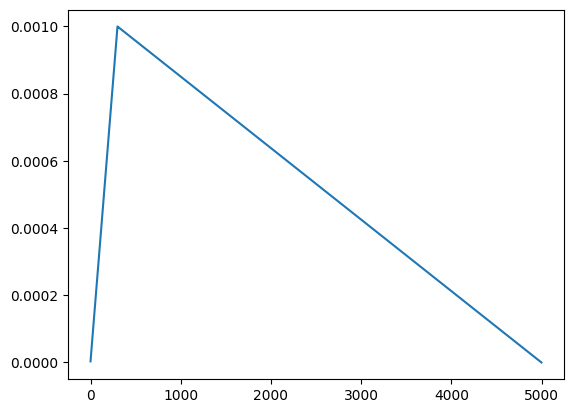

In [61]:
import torch
from torch.optim.lr_scheduler import LambdaLR
from matplotlib import pyplot as plt

def get_linear_schedule_with_warmup(
    optimizer, num_warmup_steps, num_training_steps, last_epoch=-1
):
    """Create a schedule with a learning rate that decreases linearly after
    linearly increasing during a warmup period.

    From:
        https://github.com/uds-lsv/bert-stable-fine-tuning/blob/master/src/transformers/optimization.py
    """

    def lr_lambda(current_step):
        if current_step < num_warmup_steps:
            return float(current_step) / float(max(1, num_warmup_steps))
        return max(
            0.0,
            float(num_training_steps - current_step)
            / float(max(1, num_training_steps - num_warmup_steps)),
        )

    return LambdaLR(optimizer, lr_lambda, last_epoch)
model = torch.nn.Linear(10,10)

optim = torch.optim.AdamW(model.parameters(), lr=1e-3)
lr_sch = get_linear_schedule_with_warmup(optim, 300, 5_000)
lrs = []
for i in range(5000):
    lr_sch.step()
    lrs.append(lr_sch.get_lr()[0])

plt.plot(lrs)
lrs[-2]

0.03125

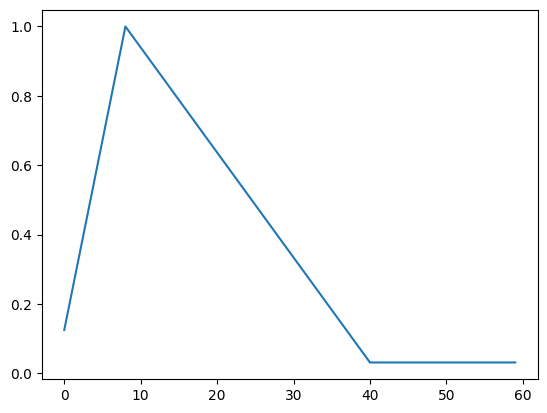

In [ ]:
from optax.schedules import linear_onecycle_schedule

trans_step = 40
schedule = linear_onecycle_schedule(
    transition_steps=trans_step,
    peak_value=1.,
    pct_start=0.2,
    pct_final=1.,
    div_factor=trans_step*0.2,
    final_div_factor=trans_step*(1-0.5))


lrs = np.array([schedule(i) for i in range(60)])
plt.plot(lrs)
lrs[-1]

0.0033333333333333335

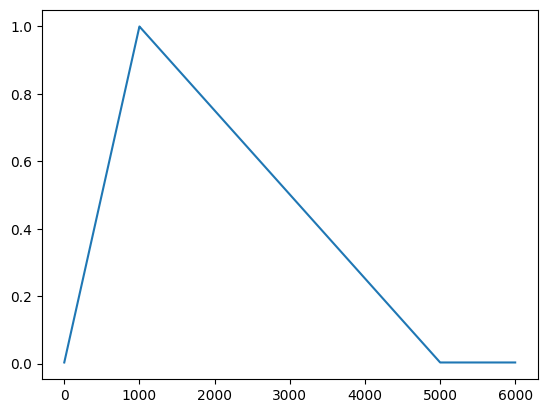

In [65]:
from optax.schedules import linear_onecycle_schedule

trans_step = 5000
schedule = linear_onecycle_schedule(
    transition_steps=trans_step,
    peak_value=1.,
    pct_start=0.2,
    pct_final=1.,
    div_factor=300,
    final_div_factor=300)


lrs = np.array([schedule(i) for i in range(6000)])
plt.plot(lrs)
lrs[-1]

#### continue

In [65]:
print(tokenizer.decode(input_ids[0], skip_special_tokens=True))
print(f"\nDecoded target: {target_id[0]} => {tokenizer.decode(target_id[0], skip_special_tokens=True)}")

Return the label of the correct answer for the question below.

Question: Ian volunteered to eat Dennis's menudo after already having a bowl because _ despised eating intestine.
Choices:
A) Ian
B) Dennis
Answer:

Decoded target: 33 => B


In [66]:
type(model.model.layers[0].self_attn)

transformers.models.qwen2.modeling_qwen2.Qwen2Attention

In [179]:
from torch import nn 

# class ForwardWrapper(nn.Module):
#     def __init__(self, model):
#         super().__init__()
#         self.model = model

#     def forward_wrapper(self, *args, **kwargs):
#         save_['in_args'] = args
#         save_['in_kwargs'] = kwargs
#         return self.model(*args, **kwargs)

save_ = {}
def my_hook(module, in1, in2, in3):
    print(module)
    save_['in2'] = in2
    save_['in1'] = in1
    save_['in3'] = in3

# model.model.layers[0].self_attn = ForwardWrapper(model.model.layers[0].self_attn)

hook_reg = model.model.layers[0].self_attn.register_forward_hook(my_hook, with_kwargs=True)
try:
    with torch.no_grad():
        torch_out = model(input_ids=torch_input_ids, attention_mask=torch_attention_mask)
finally:
    hook_reg.remove()

Qwen2Attention(
  (q_proj): Linear(in_features=896, out_features=896, bias=True)
  (k_proj): Linear(in_features=896, out_features=128, bias=True)
  (v_proj): Linear(in_features=896, out_features=128, bias=True)
  (o_proj): Linear(in_features=896, out_features=896, bias=False)
)


In [194]:
save_['in3'][0][0, 253:260]

tensor([[ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000],
        [-0.0093,  0.0082, -0.0002,  ..., -0.0021, -0.0048,  0.0034],
        [ 0.0094,  0.0002,  0.0060,  ..., -0.0061, -0.0086,  0.0107],
        ...,
        [ 0.0121, -0.0026,  0.0126,  ..., -0.0173, -0.0059,  0.0077],
        [-0.0057,  0.0026,  0.0017,  ..., -0.0049, -0.0058,  0.0156],
        [-0.0120,  0.0034, -0.0035,  ..., -0.0046, -0.0085,  0.0035]],
       device='cuda:0', dtype=torch.float16)

In [67]:
input_ids.shape, attention_mask.shape, labels.shape, target_id.shape

((2556, 300), (2556, 300), (2556,), (2556,))

In [45]:
save_['in3'][0].shape

torch.Size([4, 220, 896])

In [25]:
save_['in2'].keys()

dict_keys(['hidden_states', 'attention_mask', 'position_ids', 'past_key_values', 'use_cache', 'cache_position', 'position_embeddings'])

In [36]:
save_['in2']['position_embeddings'][0].shape

torch.Size([1, 220, 64])

In [49]:
attention_mask[:4].shape

(4, 300)

In [43]:
save_['in2']['hidden_states'].shape

torch.Size([4, 220, 896])

In [ ]:
save_['in2']['attention_mask'][0]

tensor([[[False, False, False,  ..., False, False, False],
         [False, False, False,  ..., False, False, False],
         [False, False, False,  ..., False, False, False],
         ...,
         [False, False, False,  ...,  True, False, False],
         [False, False, False,  ...,  True,  True, False],
         [False, False, False,  ...,  True,  True,  True]]], device='cuda:0')

#### compare

In [14]:
torch_last
jax_out = jnp.take_along_axis(outputs[:, -1], all_ids.reshape(1, -1), axis=-1)
torch_out = np.take_along_axis(torch_last, all_ids.reshape(1, -1), axis=-1)
print("JAX selected out:", jax_out)
print("Torch selected out:", torch_out)

JAX selected out: [[7.1   9.555]
 [7.13  9.73 ]
 [7.43  9.54 ]
 [7.297 9.664]]
Torch selected out: [[7.094 9.53 ]
 [7.133 9.734]
 [7.45  9.53 ]
 [7.26  9.62 ]]


In [108]:
torch_last
jax_out = jnp.take_along_axis(outputs[:, -1], all_ids.reshape(1, -1), axis=-1)
torch_out = np.take_along_axis(torch_last, all_ids.reshape(1, -1), axis=-1)
print("JAX selected out:", jax_out)
print("Torch selected out:", torch_out)

JAX selected out: [[ 5.887  5.652]
 [10.445  9.234]
 [ 9.36   8.11 ]
 [ 7.477  6.06 ]]
Torch selected out: [[ 8.62   9.96 ]
 [10.164 11.79 ]
 [ 9.03  10.82 ]
 [ 9.15  10.59 ]]


In [106]:
jnp.argmax(attention_mask[:4], axis=-1)

Array([112,  99, 200, 168], dtype=int32)

In [20]:
jnp.broadcast_to(causal_mask, (attention_mask.shape[0], seq_len, seq_len)).shape

(9424, 33, 33)

In [4]:
seq_len = 300
causal_mask = jnp.triu(
                jnp.ones((seq_len, seq_len), dtype=jnp.float16) * -jnp.inf, k=1)
weight = causal_mask + jax.random.normal(key=jax.random.PRNGKey(0), shape=(seq_len, seq_len))
jax.nn.softmax(weight, axis=-1)

Array([[1.0000000e+00, 0.0000000e+00, 0.0000000e+00, ..., 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00],
       [8.8795382e-01, 1.1204623e-01, 0.0000000e+00, ..., 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00],
       [3.6884800e-01, 1.3232224e-01, 4.9882972e-01, ..., 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00],
       ...,
       [4.8701251e-03, 6.8352399e-03, 1.6507380e-02, ..., 2.4016085e-03,
        0.0000000e+00, 0.0000000e+00],
       [1.7637190e-03, 1.3910775e-04, 3.2012344e-03, ..., 2.1198380e-03,
        4.8052880e-04, 0.0000000e+00],
       [1.5128745e-02, 5.9490833e-03, 7.3946971e-03, ..., 2.0531041e-04,
        1.1541211e-03, 3.3987311e-03]], dtype=float32)

In [5]:
causal_mask

Array([[  0., -inf, -inf, ..., -inf, -inf, -inf],
       [  0.,   0., -inf, ..., -inf, -inf, -inf],
       [  0.,   0.,   0., ..., -inf, -inf, -inf],
       ...,
       [  0.,   0.,   0., ...,   0., -inf, -inf],
       [  0.,   0.,   0., ...,   0.,   0., -inf],
       [  0.,   0.,   0., ...,   0.,   0.,   0.]], dtype=float16)

In [6]:
weight = jax.random.normal(key=jax.random.PRNGKey(0), shape=(4, 10, seq_len, seq_len))

In [12]:
attention_mask

Array([[0, 0, 0, ..., 1, 1, 1],
       [0, 0, 0, ..., 1, 1, 1],
       [0, 0, 0, ..., 1, 1, 1],
       ...,
       [0, 0, 0, ..., 1, 1, 1],
       [0, 0, 0, ..., 1, 1, 1],
       [0, 0, 0, ..., 1, 1, 1]], dtype=int32)

In [15]:

mask = (attention_mask[:4, None, None, :] == 0)
attn_weights2 = jnp.where(mask, -jnp.inf,  weight)
attn_weights2

Array([[[[       -inf,        -inf,        -inf, ..., -0.7116935 ,
          -0.05395174, -2.0926828 ],
         [       -inf,        -inf,        -inf, ..., -0.50935936,
           1.0135212 ,  0.60979146],
         [       -inf,        -inf,        -inf, ...,  1.2272704 ,
          -1.3195466 , -0.32613733],
         ...,
         [       -inf,        -inf,        -inf, ...,  0.12316248,
           0.8117914 , -0.1125572 ],
         [       -inf,        -inf,        -inf, ...,  0.03323483,
          -1.4509728 , -0.11996239],
         [       -inf,        -inf,        -inf, ..., -2.0630805 ,
          -0.33650947,  0.7435536 ]],

        [[       -inf,        -inf,        -inf, ..., -1.3711846 ,
           1.5841771 , -1.0049901 ],
         [       -inf,        -inf,        -inf, ..., -0.00536305,
           0.9028315 ,  1.4512507 ],
         [       -inf,        -inf,        -inf, ...,  1.1094759 ,
          -0.41762683, -0.11658346],
         ...,
         [       -inf,        -inf

In [18]:

attn_weights = jnp.where(attention_mask[:4, None, None, :], weight, -jnp.inf)
attn_weights[0,0]

Array([[       -inf,        -inf,        -inf, ..., -0.7116935 ,
        -0.05395174, -2.0926828 ],
       [       -inf,        -inf,        -inf, ..., -0.50935936,
         1.0135212 ,  0.60979146],
       [       -inf,        -inf,        -inf, ...,  1.2272704 ,
        -1.3195466 , -0.32613733],
       ...,
       [       -inf,        -inf,        -inf, ...,  0.12316248,
         0.8117914 , -0.1125572 ],
       [       -inf,        -inf,        -inf, ...,  0.03323483,
        -1.4509728 , -0.11996239],
       [       -inf,        -inf,        -inf, ..., -2.0630805 ,
        -0.33650947,  0.7435536 ]], dtype=float32)

In [20]:
weight[0,0]

Array([[ 1.6226422 ,  2.0252647 , -0.43359444, ..., -0.7116935 ,
        -0.05395174, -2.0926828 ],
       [ 0.47375467, -1.5962535 , -0.15396847, ..., -0.50935936,
         1.0135212 ,  0.60979146],
       [ 0.399992  , -0.62515265,  0.7018721 , ...,  1.2272704 ,
        -1.3195466 , -0.32613733],
       ...,
       [ 0.8301435 ,  1.1691153 ,  2.0508313 , ...,  0.12316248,
         0.8117914 , -0.1125572 ],
       [-0.15068035, -2.6906116 ,  0.44543153, ...,  0.03323483,
        -1.4509728 , -0.11996239],
       [ 2.236748  ,  1.3033886 ,  1.5209146 , ..., -2.0630805 ,
        -0.33650947,  0.7435536 ]], dtype=float32)

In [17]:
jnp.allclose(attn_weights, attn_weights2)

Array(True, dtype=bool)

In [38]:
causal_mask = causal_mask.at[:, attention_mask[0] == 0].set(-np.inf)
causal_mask

Array([[-inf, -inf, -inf, ..., -inf, -inf, -inf],
       [-inf, -inf, -inf, ..., -inf, -inf, -inf],
       [-inf, -inf, -inf, ..., -inf, -inf, -inf],
       ...,
       [-inf, -inf, -inf, ...,   0., -inf, -inf],
       [-inf, -inf, -inf, ...,   0.,   0., -inf],
       [-inf, -inf, -inf, ...,   0.,   0.,   0.]], dtype=float16)

In [33]:
causal_mask

Array([[  0., -inf, -inf, ..., -inf, -inf, -inf],
       [  0.,   0., -inf, ..., -inf, -inf, -inf],
       [  0.,   0.,   0., ..., -inf, -inf, -inf],
       ...,
       [  0.,   0.,   0., ...,   0., -inf, -inf],
       [  0.,   0.,   0., ...,   0.,   0., -inf],
       [  0.,   0.,   0., ...,   0.,   0.,   0.]], dtype=float16)

In [ ]:
selected = jnp.take_along_axis(outputs[:, -1], all_ids.reshape(1, -1), axis=-1)
selected

Array([[ 5.887,  5.652],
       [10.445,  9.234],
       [ 9.36 ,  8.11 ],
       [ 7.477,  6.06 ]], dtype=float16)

### with subspace model wrapper

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "1"
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"] = ".99"




In [2]:
import torch
from transformers import AutoTokenizer
from transformers import AutoModelForCausalLM

# Model name used in the torch notebook
MODEL_NAME = "Qwen/Qwen2.5-0.5B"
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Target Device:", device)

# Load tokenizer and model (trust_remote_code matches torch notebook)
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, trust_remote_code=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

Target Device: cuda


In [3]:
import jax
import jax.numpy as jnp
from qwen_fineTuning_PtoC import QwenTextClassificationWrapper
import numpy as np
from flax.core import freeze, unfreeze

%load_ext autoreload
%autoreload 2

# with np.load("datasets/text_classification/boolq/train_data.npz") as data:
with np.load("datasets/text_classification/winogrande_s/test_data.npz") as data:
    input_ids = jnp.array(data['input_ids'])
    attention_mask = jnp.array(data['attention_mask'])
    labels = jnp.array(data['labels'])
    target_id = jnp.array(data['target_id'])
    all_target_ids = jnp.array(data['target_ids'])

input_ids.shape, attention_mask.shape, labels.shape, target_id.shape, all_target_ids.shape

((1264, 64), (1264, 64), (1264,), (1264,), (2, 1))

In [4]:

model = QwenTextClassificationWrapper("datasets/model_exports/qwen2.5_0.5B_bfloat16", target_token_ids=all_target_ids)

params = model.init(None, None)
params = unfreeze(params)
params

{'params': {'embed_tokens': {'embedding': Array([[-0.0100708, 0.0419922, 0.0098877, ..., 0.00994873, 0.0151367,
           -0.00704956],
          [-0.0146484, 6.03199e-05, -0.0184326, ..., -0.00169373,
           0.00311279, -0.00842285],
          [-0.0366211, -0.00982666, 0.00698853, ..., -0.00775146,
           -0.0170898, -0.000104904],
          ...,
          [0.0027771, -0.00939941, 0.00424194, ..., -0.00656128, -0.0106201,
           0.0172119],
          [0.0027771, -0.00939941, 0.00424194, ..., -0.00656128, -0.0106201,
           0.0172119],
          [0.0027771, -0.00939941, 0.00424194, ..., -0.00656128, -0.0106201,
           0.0172119]], dtype=bfloat16)},
  'layers_0': {'input_layernorm': {'weight': Array([-0.0461426, 0.0437012, -0.0244141, 0.0825195, -0.0410156,
           0.0375977, -0.0397949, -0.0267334, -0.105469, -0.0302734,
           0.0441895, -0.0490723, -0.0283203, 0.0354004, 0.0534668, 0.101562,
           0.108398, -0.0476074, 0.223633, 0.108398, 0.112305, -0

In [5]:
logits = model.apply(params, input_ids[:6], attention_mask[:6], train=False)
logits

Array([[6.71875, 8.625],
       [6.65625, 8.5625],
       [5.78125, 9.5],
       [6.25, 9.6875],
       [6.53125, 9.25],
       [6.25, 9.5]], dtype=bfloat16)

In [6]:
print(tokenizer.decode(input_ids[1138], skip_special_tokens=True))

Return the label of the correct answer for the question below.

Question: Katrina did not value the antique pictures as much as Lindsey because _ was a history buff.
Choices:
A) Katrina
B) Lindsey
Answer:


In [ ]:
from src.subspace_curve import CategorySubspace, filter_mask, LoRACategorySubspace

key = jax.random.PRNGKey(0)
s_model = CategorySubspace(model, k=2)

curve_mask = jax.tree.map(lambda x: False, params)['params']
curve_mask = filter_mask(curve_mask, "self_attn", "q_proj", "kernel", as_curve=True)
curve_mask = filter_mask(curve_mask, "self_attn", "v_proj", "kernel", as_curve=True)

train_mask = jax.tree.map(lambda x: False, params['params'])
train_mask = filter_mask(train_mask, "self_attn", "q_proj", "kernel", as_curve=True)
train_mask = filter_mask(train_mask, "self_attn", "v_proj", "kernel", as_curve=True)

s_params = s_model.init_params_from_point(key, params, curve_mask, noise_fn=lambda p, key: p)
del params
s_model.set_train_mask(train_mask)
s_model(s_params['params'], {}, 0.5, (input_ids[:12], attention_mask[:12]), train=False)


In [5]:
# with lora
from src.subspace_curve import CategorySubspace, filter_mask, LoRACategorySubspace

lora_mask = jax.tree.map(lambda x: False, params)['params']
lora_mask = filter_mask(lora_mask, "self_attn", "q_proj", "kernel", as_curve=np.array([1,0]))
lora_mask = filter_mask(lora_mask, "self_attn", "v_proj", "kernel", as_curve=np.array([1,0]))

key = jax.random.PRNGKey(0)
s_model = LoRACategorySubspace(model=model, k=2, lora_mask=lora_mask, r=8, lora_dtype='float32', lora_alpha=16.)

curve_mask = jax.tree.map(lambda x: False, params)['params']
curve_mask = filter_mask(curve_mask, "self_attn", "q_proj", "kernel", as_curve=True)
curve_mask = filter_mask(curve_mask, "self_attn", "v_proj", "kernel", as_curve=True)

train_mask = jax.tree.map(lambda x: False, params['params'])
train_mask = filter_mask(train_mask, "self_attn", "q_proj", "kernel", as_curve=True)
train_mask = filter_mask(train_mask, "self_attn", "v_proj", "kernel", as_curve=True)

s_params = s_model.init_params_from_point(key, params, curve_mask, noise_fn=lambda p, key: p)
del params

s_model.set_train_mask(train_mask)
s_model(s_params['params'], {}, 0.5, (input_ids[:12], attention_mask[:12]), train=False)

(Array([[ 6.53125,  8.375  ],
        [ 6.53125,  8.375  ],
        [ 5.78125,  9.5625 ],
        [ 6.46875,  9.875  ],
        [ 6.625  ,  9.3125 ],
        [ 6.15625,  9.3125 ],
        [ 7.375  , 10.875  ],
        [ 7.375  , 10.4375 ],
        [ 6.53125,  8.6875 ],
        [ 6.09375, 10.375  ],
        [ 6.03125, 10.25   ],
        [ 7.3125 ,  9.5625 ]], dtype=float32),
 {})

In [14]:
s_params['params']['layers_0']['self_attn']['q_proj']['kernel'].shape

{'A': (3, 8, 896), 'B': (896, 8), 'w0': (896, 896)}

In [15]:
s_params['params']['layers_0']['self_attn']['v_proj']['kernel'].shape

{'A': (3, 8, 896), 'B': (128, 8), 'w0': (896, 128)}

In [16]:
print(s_params['params']['layers_0']['self_attn']['q_proj']['kernel'].A.dtype)
print(s_params['params']['layers_0']['self_attn']['q_proj']['kernel'].B.dtype)
print(s_params['params']['layers_0']['self_attn']['q_proj']['kernel'].w0.dtype)

float32
float32
bfloat16


In [17]:
from qwen_fineTuning_PtoC import setup_metrics

metrics = setup_metrics(s_model, 4, input_ids[:12], attention_mask[:12], labels[:12], 1, use_linspace=True, average=True)
metrics(key, s_params)

{'loss': Array(1.63281, dtype=bfloat16),
 'acc': Array(0.5, dtype=float32),
 'ece': Array(0.4733073, dtype=float32)}

In [70]:
from optax import adamw


optimizer = adamw(1e-5)
trainable_params = s_model.only_trainable_params(s_params['params'])
opt_state = optimizer.init(trainable_params)

In [18]:
sub_key = jax.random.PRNGKey(1)
loss, params, opt_state, grad_ = s_model.train_step(
                    sub_key, params, (input_ids[:4], attention_mask[:4]), labels[:4], opt_state, optimizer)
loss

Array(1.82812, dtype=bfloat16)